In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, IFrame, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
RES = ROOT / "results"
def show_png(path, width=620):
    display(Image(filename=str(path), width=width))

# 02 · Per-point labels, candidate generation and features
Partitions: **train** and **student_test**. Code: `data_processing/label_points.py`, `features/candidates.py`,
`features/build_features.py`.

## 1. From `.route` to one reference arc per GPS point
`.route` lists the arcs travelled but not which arc each GPS point is on. For point *i* we choose a route index `j_i`
that never decreases, minimising the total point-to-arc distance:

`C[i][j] = d[i][j] + min_{k <= j} C[i-1][k]` (running prefix-minimum, O(N × R)), then back-track.

A greedy nearest-arc rule would let one noisy point drag the index forward and force every later point onto that arc.

00000007 1354 points


,point_idx,arc_id,route_idx,dist_m
0,0,520,0,0.214719
1,1,520,0,1.112471
2,2,520,0,3.735155
3,3,520,0,0.008900
4,4,2166,1,5.649207


route index never decreases: True
distance to labelled arc (m): median 4.5, p95 26.2, max 36.8


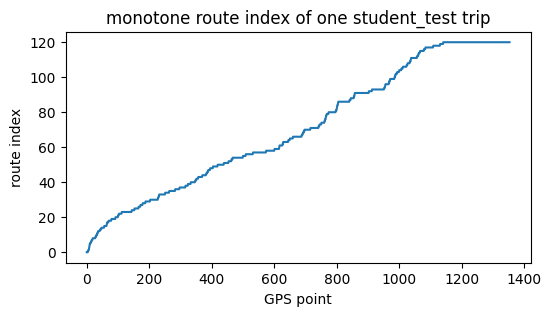

In [2]:
from common.io import list_trips
from data_processing.label_points import label_trip
trip = list_trips("student_test")[1]
lab = label_trip(trip)
print(trip.name, len(lab), "points")
display(lab.head())
print("route index never decreases:", bool((np.diff(lab.route_idx) >= 0).all()))
print("distance to labelled arc (m): median %.1f, p95 %.1f, max %.1f" % (lab.dist_m.median(), lab.dist_m.quantile(.95), lab.dist_m.max()))
plt.figure(figsize=(6,3)); plt.plot(lab.route_idx.values); plt.xlabel("GPS point"); plt.ylabel("route index"); plt.title("monotone route index of one student_test trip"); plt.show()

## 2. Candidate generation: radius and K
Candidates are the nearest `K` arcs within `RADIUS_M` of each point (STRtree on arcs in metres), with a fallback to the nearest `K` when none is in range; the reverse twin of every kept arc is kept too. The **candidate miss rate** (reference arc absent from the candidates) caps accuracy.

In [3]:
sw = pd.read_csv(RES / "eda/candidate_sweep.csv")
display(sw.pivot(index="k", columns="radius_m", values="miss_rate").round(4))
display(sw.pivot(index="k", columns="radius_m", values="mean_rows_per_point").round(2))
display(pd.read_csv(RES / "eda/feature_build_stats.csv"))

radius_m,30,60,100
k,,,
8,0.0807,0.0790,0.1065
12,0.0719,0.0704,0.1029
16,0.0660,0.0647,0.1017


radius_m,30,60,100
k,,,
8,5.03,6.31,6.69
12,5.92,8.13,9.07
16,6.56,9.53,11.06


,split,trips,points,rows,miss_rate,miss_twin_only_share,mean_rows_per_point,positive_share,sec_per_trip,k,radius_m
0,train,80,208417,1314688,0.078957,0.0,6.307969,0.146013,0.438833,8,60.0
1,student_test,10,19160,122193,0.003706,0.0,6.377505,0.156220,0.242925,8,60.0


## 3. Features (one row per GPS point × candidate arc)
| feature | meaning | why it helps |
|---|---|---|
| `dist_m`, `dist_rank`, `dist_minus_min` | distance to the arc, its rank, and the gap to the nearest candidate | nearest is usually right; the gap tells how ambiguous the point is |
| `heading_diff` (0–180°) | GPS heading vs the **directed** arc bearing | separates an arc from its reverse twin (0° vs 180°) |
| `low_speed` | heading is unreliable at low speed (then `heading_diff` = 90) | stops a noisy heading from misleading the model |
| `speed_mps`, `dt_s` | speed and time since previous fix | context for gaps and stops |
| `arc_len_m`, `proj_t` | arc length and position of the projection along the arc | where on the arc the point falls |
| `has_twin`, `fallback` | reverse arc exists; no candidate was in range | flags ambiguous / out-of-range situations |
| `connects_prev_best` | arc equals or directly follows the previous point's best arc | injects road connectivity into the classifier |

`trip_id`, `point_idx`, `t`, `lon`, `lat` and `arc_id` are identifiers/location and are **not** model inputs.

In [4]:
from features.build_features import FEATURE_COLUMNS, METADATA_COLUMNS
print("model inputs:", FEATURE_COLUMNS)
print("kept for joining/mapping only:", METADATA_COLUMNS)
tbl = pd.read_parquet(ROOT / "data/processed/student_test_features.parquet")
print(tbl.shape)
display(tbl.head(6))

model inputs: ['dist_m', 'dist_rank', 'dist_minus_min', 'heading_diff', 'speed_mps', 'dt_s', 'arc_len_m', 'proj_t', 'fallback', 'low_speed', 'has_twin', 'connects_prev_best']
kept for joining/mapping only: ['trip_id', 'point_idx', 't', 'lon', 'lat', 'arc_id']


(122193, 19)


,trip_id,point_idx,t,lon,lat,arc_id,dist_m,dist_rank,dist_minus_min,heading_diff,speed_mps,dt_s,arc_len_m,proj_t,fallback,low_speed,has_twin,connects_prev_best,label
0,00000000,0,1.0,54.963519,56.251559,17630,6.114291,0,0.000000,14.067254,23.644427,1.0,358.420308,0.872796,False,0,1,0,1
1,00000000,0,1.0,54.963519,56.251559,17634,6.114291,0,0.000000,165.932746,23.644427,1.0,358.420308,0.127204,False,0,1,0,0
2,00000000,0,1.0,54.963519,56.251559,17635,27.673402,2,21.559111,149.445275,23.644427,1.0,262.755748,0.139847,False,0,1,0,0
3,00000000,0,1.0,54.963519,56.251559,17668,27.673402,2,21.559111,30.554725,23.644427,1.0,262.755748,0.860153,False,0,1,0,0
4,00000000,0,1.0,54.963519,56.251559,212,46.000553,4,39.886262,165.816706,23.644427,1.0,33.193140,1.000000,False,0,1,0,0
5,00000000,0,1.0,54.963519,56.251559,17633,46.000553,4,39.886262,14.183294,23.644427,1.0,33.193140,0.000000,False,0,1,0,0


## 4. Which features matter? (permutation importance of the selected model on student_test)

,feature,top1_drop_mean,top1_drop_std
0,heading_diff,0.35063,0.00467
1,dist_minus_min,0.12288,0.00327
2,proj_t,0.05529,0.00161
3,dist_m,0.01329,0.00230
4,connects_prev_best,0.01166,0.00094
5,speed_mps,0.00705,0.00085
6,has_twin,0.00609,0.00147
7,arc_len_m,0.00379,0.00034
8,dist_rank,0.00073,0.00052
9,dt_s,0.00019,0.00007


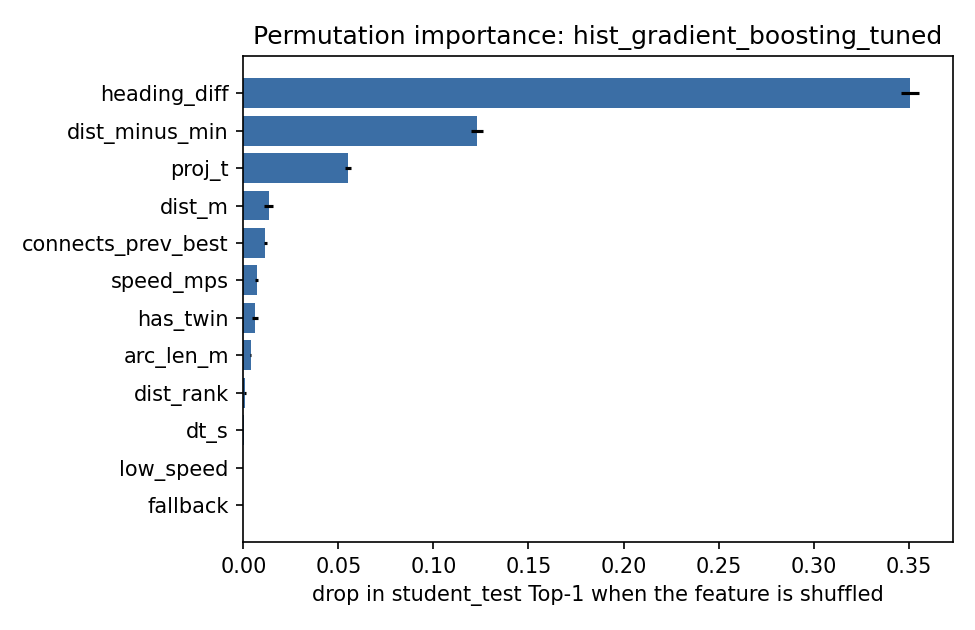

Shuffling heading_diff costs 0.351 Top-1: direction information is the strongest signal.


In [5]:
display(pd.read_csv(RES / "feature_importance.csv"))
show_png(RES / "figures/model_feature_importance.png", 520)
top = pd.read_csv(RES / "feature_importance.csv").iloc[0]
print(f"Shuffling {top.feature} costs {top.top1_drop_mean:.3f} Top-1: direction information is the strongest signal.")